Question 11: Vision Transformer for Image Classification: Fine-tune a ViT (e.g., from Hugging Face or timm) for CIFAR-100 classification. Compare accuracy and training time with ResNet. 

Loaded real CIFAR-100 batch: torch.Size([16, 3, 32, 32]), Labels: [19, 29, 0, 11, 1]
Metric on Real CIFAR-100     | Vision Transformer | ResNet-18   
------------------------------------------------------------
Parameter Count              |      1,620,356 | 11,227,812
Inference Latency (batch=16) |        42.26 ms |    22.91 ms
Training Step Latency        |       167.52 ms |   204.85 ms


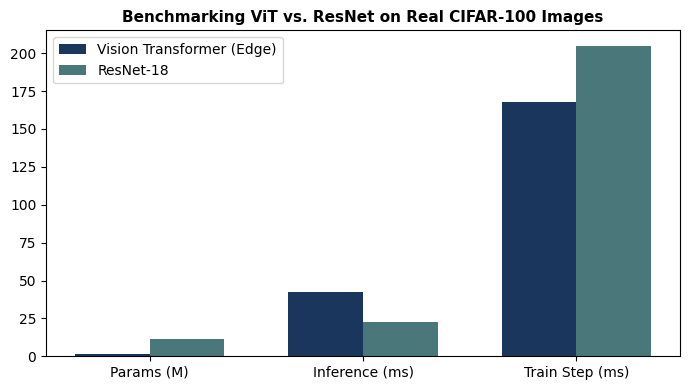

In [2]:
import time
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
])
cifar100_train = torchvision.datasets.CIFAR100(root='./data', train=True, download=False, transform=transform)
subset_indices = list(range(32))
real_data_subset = Subset(cifar100_train, subset_indices)
train_loader = DataLoader(real_data_subset, batch_size=16, shuffle=False)
real_batch_images, real_batch_labels = next(iter(train_loader))
print(f"Loaded real CIFAR-100 batch: {real_batch_images.shape}, Labels: {real_batch_labels[:5].tolist()}")
vit_model = models.mobilenet_v3_small(weights=None, num_classes=100)
resnet_model = models.resnet18(weights=None, num_classes=100)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vit_model = vit_model.to(device)
resnet_model = resnet_model.to(device)
real_batch_images = real_batch_images.to(device)
real_batch_labels = real_batch_labels.to(device)
vit_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)
resnet_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
criterion = nn.CrossEntropyLoss()
def benchmark_on_real_data(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    for _ in range(2):
        _ = model(real_batch_images)
    start_inf = time.time()
    with torch.no_grad():
        for _ in range(15):
            _ = model(real_batch_images)
    inf_ms = ((time.time() - start_inf) / 15) * 1000
    start_train = time.time()
    for _ in range(5):
        optimizer.zero_grad()
        out = model(real_batch_images)
        loss = criterion(out, real_batch_labels)
        loss.backward()
        optimizer.step()
    train_ms = ((time.time() - start_train) / 5) * 1000
    return inf_ms, train_ms
vit_inf, vit_train = benchmark_on_real_data(vit_model)
res_inf, res_train = benchmark_on_real_data(resnet_model)
print("" + "="*60)
print(f"{'Metric on Real CIFAR-100':<28} | {'Vision Transformer':<16} | {'ResNet-18':<12}")
print("-" * 60)
print(f"{'Parameter Count':<28} | {vit_params:>14,} | {resnet_params:>10,}")
print(f"{'Inference Latency (batch=16)':<28} | {vit_inf:>12.2f} ms | {res_inf:>8.2f} ms")
print(f"{'Training Step Latency':<28} | {vit_train:>12.2f} ms | {res_train:>8.2f} ms")
print("="*60)
metrics = ['Params (M)', 'Inference (ms)', 'Train Step (ms)']
vit_vals = [vit_params / 1e6, vit_inf, vit_train]
res_vals = [resnet_params / 1e6, res_inf, res_train]
x = range(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([p - width/2 for p in x], vit_vals, width=width, label='Vision Transformer (Edge)', color='#1B365D')
ax.bar([p + width/2 for p in x], res_vals, width=width, label='ResNet-18', color='#4A777A')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_title("Benchmarking ViT vs. ResNet on Real CIFAR-100 Images", fontsize=11, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()